# Dense-sparse compiler consistency

Reproduce all six panels from `data/3D/dense_sparse_consistency.txt`.
The notebook calls the original `setup_plot.py` and uses a **17.9 cm x 11.6 cm** canvas
with **8 pt** text. It exports a vector PDF and a 600 dpi PNG without tight cropping,
so the saved PDF retains the requested physical width.

The data contain one phase realization per qubit count. No uncertainty bars or
spectral fits are added. Compilation time excludes statevector and field validation.
Peak worker memory includes interpreter/import overhead and uses decimal GB.
Infidelity is calculated from the full-precision JSON record, not the rounded
summary table. The velocity spectra are the stored unweighted shell sums. Zero
entries are omitted from logarithmic axes; no spectral smoothing is applied.

Run the cells from top to bottom. Dependencies: NumPy, pandas, Matplotlib, and the
LaTeX installation required by `setup_plot.py` (including `sansmathfonts`).
The sparse occupied-prefix count includes the root and leaves, as defined in the source.


In [ ]:
from io import StringIO
from pathlib import Path
import json
import re
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import (
    FixedLocator, LogFormatterMathtext, LogLocator,
    NullFormatter, NullLocator, ScalarFormatter,
)

PROJECT_ROOT = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / "setup_plot.py").is_file()
     and (directory / "data/3D/dense_sparse_consistency.txt").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the QuanEncodeTurb project.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from setup_plot import setup_plot

setup_plot(fontsize=8, fonttype="sans-serif", dpi=150)
mpl.rcParams.update({
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.5,
    "lines.linewidth": 0.8,
    "savefig.bbox": None,
    "savefig.pad_inches": 0,
})

DATA_PATH = PROJECT_ROOT / "data/3D/dense_sparse_consistency.txt"
OUTPUT_DIR = PROJECT_ROOT / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_WIDTH_CM = 17.9
FIGURE_HEIGHT_CM = 11.6
EXPORT_DPI = 600
SPECTRUM_QUBITS = 30


In [2]:
def read_consistency_data(path):
    """Read the sectioned benchmark file without rounding its JSON values."""
    text = path.read_text(encoding="utf-8-sig")
    headers = list(re.finditer(r"^\[([^\]\r\n]+)\]\s*$", text, re.MULTILINE))
    cases = {}
    definition = None
    current_case = None

    for index, match in enumerate(headers):
        section = match.group(1)
        stop = headers[index + 1].start() if index + 1 < len(headers) else len(text)
        body = text[match.end():stop].strip()

        if section == "BENCHMARK_DEFINITION":
            definition = json.loads(body)
        elif section.startswith("CASE n="):
            n = int(section.split("=", 1)[1])
            if n in cases:
                raise ValueError(f"Duplicate case n={n}.")
            current_case = json.loads(body)
            cases[n] = current_case
        elif section in {
            "DENSE_COMPILATION", "SPARSE_COMPILATION", "DENSE_SPARSE_DIFFERENCES",
        }:
            if current_case is None:
                raise ValueError(f"Section {section} has no associated case.")
            current_case[section] = json.loads(body)
        elif section == "VELOCITY_ENERGY_SPECTRA":
            if current_case is None:
                raise ValueError("Spectrum has no associated case.")
            spectrum = pd.read_csv(StringIO(body), sep=r"\s+")
            if list(spectrum.columns) != ["k", "E_dense", "E_sparse"]:
                raise ValueError("Unexpected spectrum column names.")
            if not np.isfinite(spectrum.to_numpy()).all():
                raise ValueError("Spectrum contains nonfinite entries.")
            if not np.all(np.diff(spectrum["k"]) > 0):
                raise ValueError("Spectrum wavenumbers are not strictly increasing.")
            if (spectrum[["E_dense", "E_sparse"]] < 0).any().any():
                raise ValueError("Spectrum contains negative energies.")
            current_case[section] = spectrum

    if definition is None or sorted(cases) != sorted(definition["n_values"]):
        raise ValueError("Case list does not match the benchmark definition.")

    rows = []
    for n, case in sorted(cases.items()):
        dense = case["DENSE_COMPILATION"]
        sparse = case["SPARSE_COMPILATION"]
        difference = case["DENSE_SPARSE_DIFFERENCES"]
        fidelity = difference["minimum_component_fidelity"]
        if not 0 <= fidelity <= 1:
            raise ValueError(f"Invalid component fidelity at n={n}.")
        rows.append({
            "n": n,
            "dense_time_s": dense["compilation_time_s"],
            "sparse_time_s": sparse["compilation_time_s"],
            "dense_memory_GB": dense["peak_memory_GB"],
            "sparse_memory_GB": sparse["peak_memory_GB"],
            "retained_modes": sparse["retained_modes"],
            "occupied_prefixes": sparse["occupied_prefixes"],
            "component_infidelity": 1.0 - fidelity,
            "spin_difference": difference["spin_relative_L2_difference"],
            "velocity_difference": difference["velocity_relative_L2_difference"],
            "vorticity_difference": difference["vorticity_relative_L2_difference"],
            "spectrum_difference": difference["energy_spectrum_relative_L2_difference"],
        })

    summary = pd.DataFrame(rows).sort_values("n").reset_index(drop=True)
    if not np.isfinite(summary.to_numpy()).all():
        raise ValueError("Summary contains nonfinite entries.")
    if not (summary.drop(columns="n") > 0).all().all():
        raise ValueError("This plot expects positive benchmark values.")
    return definition, cases, summary


definition, cases, summary = read_consistency_data(DATA_PATH)
spectrum = cases[SPECTRUM_QUBITS]["VELOCITY_ENERGY_SPECTRA"]
print(f"Loaded {len(summary)} cases from {DATA_PATH.relative_to(PROJECT_ROOT)}")
print(f"Phase realizations per qubit count: {definition['phase_realizations_per_n']}")
print(f"Velocity spectrum: n={SPECTRUM_QUBITS}, {len(spectrum)} stored shells")


Loaded 6 cases from data\run1time\run01\data\3D\dense_sparse_consistency.txt
Phase realizations per qubit count: 1
Velocity spectrum: n=30, 1024 stored shells


In [3]:
# Palette and markers follow the manuscript's circuit-depth and spectrum plots.
RED, PALE_RED = "#CE5044", "#FFE9F1"
BLUE, PALE_BLUE = "#7AA7D3", "#DDE9F5"
GREEN, PALE_GREEN = "#86B6A4", "#DFEDDC"
PURPLE, PALE_PURPLE = "#A486BE", "#EAE0F2"

cm = 1 / 2.54
fig = plt.figure(figsize=(FIGURE_WIDTH_CM * cm, FIGURE_HEIGHT_CM * cm))

# Physical positions in centimetres preserve the exact canvas dimensions.
left_cm = 1.35
right_cm = 0.25
gap_cm = 1.55
axes_width_cm = (FIGURE_WIDTH_CM - left_cm - right_cm - 2 * gap_cm) / 3
axes_height_cm = 4.0
row_bottoms_cm = [7.0, 1.15]
axes = []
for bottom in row_bottoms_cm:
    for column in range(3):
        left = left_cm + column * (axes_width_cm + gap_cm)
        axes.append(fig.add_axes([
            left / FIGURE_WIDTH_CM,
            bottom / FIGURE_HEIGHT_CM,
            axes_width_cm / FIGURE_WIDTH_CM,
            axes_height_cm / FIGURE_HEIGHT_CM,
        ]))

n = summary["n"].to_numpy()


def style_axes(ax, letter, title, qubit_axis=True):
    ax.grid(color="k", linestyle="-", linewidth=0.5, alpha=0.1, which="major")
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_linewidth(0.5)
    ax.tick_params(
        axis="x", which="major", direction="out", top=False,
        length=3, width=0.5, pad=1.5,
    )
    ax.tick_params(
        axis="y", which="major", direction="out", right=False,
        length=3, width=0.5, pad=1,
    )
    ax.tick_params(
        which="minor", direction="out", top=False, right=False,
        length=1.5, width=0.5,
    )
    ax.set_title(title, fontsize=8, pad=6, y=1.0)
    ax.text(
        -0.23, 1.045, rf"\textbf{{{letter}}}",
        transform=ax.transAxes, fontsize=8, va="bottom", ha="left",
    )
    if qubit_axis:
        ax.set_xlim(14.2, 30.8)
        ax.set_xticks(n)
        ax.set_xlabel(r"Number of qubits, $n$", fontsize=8, labelpad=1)


def series(ax, x, y, label, edge, face, marker="o"):
    return ax.plot(
        x, y, label=label, color=edge, linewidth=0.8,
        linestyle="-", marker=marker, markersize=4,
        markerfacecolor=face, markeredgecolor=edge, markeredgewidth=0.7,
    )


def legend(ax, **kwargs):
    leg = ax.legend(
        fontsize=8, frameon=True, fancybox=False, framealpha=0.9,
        edgecolor="#D0D0D0", borderpad=0.3, labelspacing=0.25,
        handlelength=1.5, handletextpad=0.4, borderaxespad=0.4,
        **kwargs,
    )
    leg.get_frame().set_linewidth(0.5)
    return leg


def log_y(ax, ticks):
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(FixedLocator(ticks))
    ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
    ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10)))
    ax.yaxis.set_minor_formatter(NullFormatter())


# a. Classical compilation time only.
ax = axes[0]
style_axes(ax, "a", "Compilation time")
log_y(ax, [1e-2, 1e-1, 1, 10, 100])
series(ax, n, summary["dense_time_s"], "Dense", RED, PALE_RED)
series(ax, n, summary["sparse_time_s"], "Sparse", BLUE, PALE_BLUE, marker="d")
ax.set_ylim(8e-3, 150)
ax.set_ylabel("Time (s)", labelpad=2)
legend(ax, loc="upper left")

# b. Worker peak RSS includes interpreter/import overhead; 1 GB = 10^9 bytes.
ax = axes[1]
style_axes(ax, "b", "Peak worker memory")
log_y(ax, [1e-1, 1, 10, 100])
series(ax, n, summary["dense_memory_GB"], "Dense", RED, PALE_RED)
series(ax, n, summary["sparse_memory_GB"], "Sparse", BLUE, PALE_BLUE, marker="d")
ax.set_ylim(0.1, 160)
ax.set_ylabel("Peak memory (GB)", labelpad=2)
legend(ax, loc="upper left")

# c. Axis unit is 10^4 counts; the stored integers remain unchanged.
ax = axes[2]
style_axes(ax, "c", "Sparse representation")
series(ax, n, summary["retained_modes"] / 1e4,
       "Retained modes", BLUE, PALE_BLUE)
series(ax, n, summary["occupied_prefixes"] / 1e4,
       "Occupied prefixes", RED, PALE_RED, marker="s")
ax.set_ylim(2, 8.2)
ax.set_yticks([2, 4, 6, 8])
ax.set_ylabel(r"Count ($10^4$)", labelpad=2)
legend(ax, loc="center right", bbox_to_anchor=(1.0, 0.56))

# d. Minimum of the two squared component overlaps, at full JSON precision.
ax = axes[3]
style_axes(ax, "d", "Component infidelity")
series(ax, n, summary["component_infidelity"], None, BLUE, PALE_BLUE)
ax.set_ylim(0.75e-14, 1.075e-14)
ax.set_yticks(np.array([0.8, 0.9, 1.0]) * 1e-14)
formatter = ScalarFormatter(useMathText=True, useOffset=False)
formatter.set_scientific(True)
formatter.set_powerlimits((-14, -14))
ax.yaxis.set_major_formatter(formatter)
ax.yaxis.get_offset_text().set_visible(False)
ax.text(0.03, 0.97, r"$\times 10^{-14}$", transform=ax.transAxes,
        fontsize=8, ha="left", va="top")
ax.yaxis.set_minor_locator(NullLocator())
ax.set_ylabel(r"$1-F_{\min}$", labelpad=2)

# e. Relative L2 differences use the dense reference as the denominator.
ax = axes[4]
style_axes(ax, "e", "Decoded-field agreement")
log_y(ax, [1e-8, 1e-7, 1e-6, 1e-5])
series(ax, n, summary["spin_difference"], "Spin", BLUE, PALE_BLUE)
series(ax, n, summary["velocity_difference"], "Velocity", RED, PALE_RED, marker="s")
series(ax, n, summary["vorticity_difference"], "Vorticity", GREEN, PALE_GREEN, marker="^")
series(ax, n, summary["spectrum_difference"], "Spectrum", PURPLE, PALE_PURPLE, marker="d")
ax.set_ylim(1e-8, 2e-5)
ax.set_ylabel(r"Relative $L^2$ difference", labelpad=2)
legend(ax, loc="upper left")

# f. Every positive stored shell; no fitting, smoothing, or k premultiplication.
ax = axes[5]
style_axes(ax, "f", rf"Velocity spectrum ($n={SPECTRUM_QUBITS}$)", qubit_axis=False)
ax.set_xscale("log")
log_y(ax, [1e-8, 1e-6, 1e-4, 1e-2, 1])
for column, label, color, linestyle in [
    ("E_dense", "Dense", RED, "-"),
    ("E_sparse", "Sparse", BLUE, "--"),
]:
    valid = (spectrum["k"] > 0) & (spectrum[column] > 0)
    ax.plot(
        spectrum.loc[valid, "k"], spectrum.loc[valid, column],
        color=color, linestyle=linestyle, linewidth=1.0, label=label,
    )
ax.set_xlim(1, 2 ** (SPECTRUM_QUBITS // 3))
ax.set_ylim(1e-9, 10)
ax.xaxis.set_major_locator(FixedLocator([1, 10, 100, 1000]))
ax.xaxis.set_major_formatter(LogFormatterMathtext(base=10))
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10)))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel(r"Wavenumber, $k$", labelpad=1)
ax.set_ylabel(r"$E_k$", labelpad=2)
legend(ax, loc="lower left")

# Check for clipping before export. Do not crop or rescale the canvas.
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
for index, ax in enumerate(axes):
    bounds = ax.get_tightbbox(renderer).transformed(fig.transFigure.inverted())
    if bounds.x0 < 0 or bounds.y0 < 0 or bounds.x1 > 1 or bounds.y1 > 1:
        raise RuntimeError(f"Panel {index + 1} extends outside the canvas: {bounds}")
assert np.isclose(fig.get_figwidth() * 2.54, FIGURE_WIDTH_CM)
assert np.isclose(fig.get_figheight() * 2.54, FIGURE_HEIGHT_CM)


Saved vector PDF: C:\codex\QuanEncodeTurb\figures\dense_sparse_consistency.pdf
Saved 600 dpi PNG: C:\codex\QuanEncodeTurb\figures\dense_sparse_consistency.png
Canvas: 17.9 cm x 11.6 cm; text: 8 pt


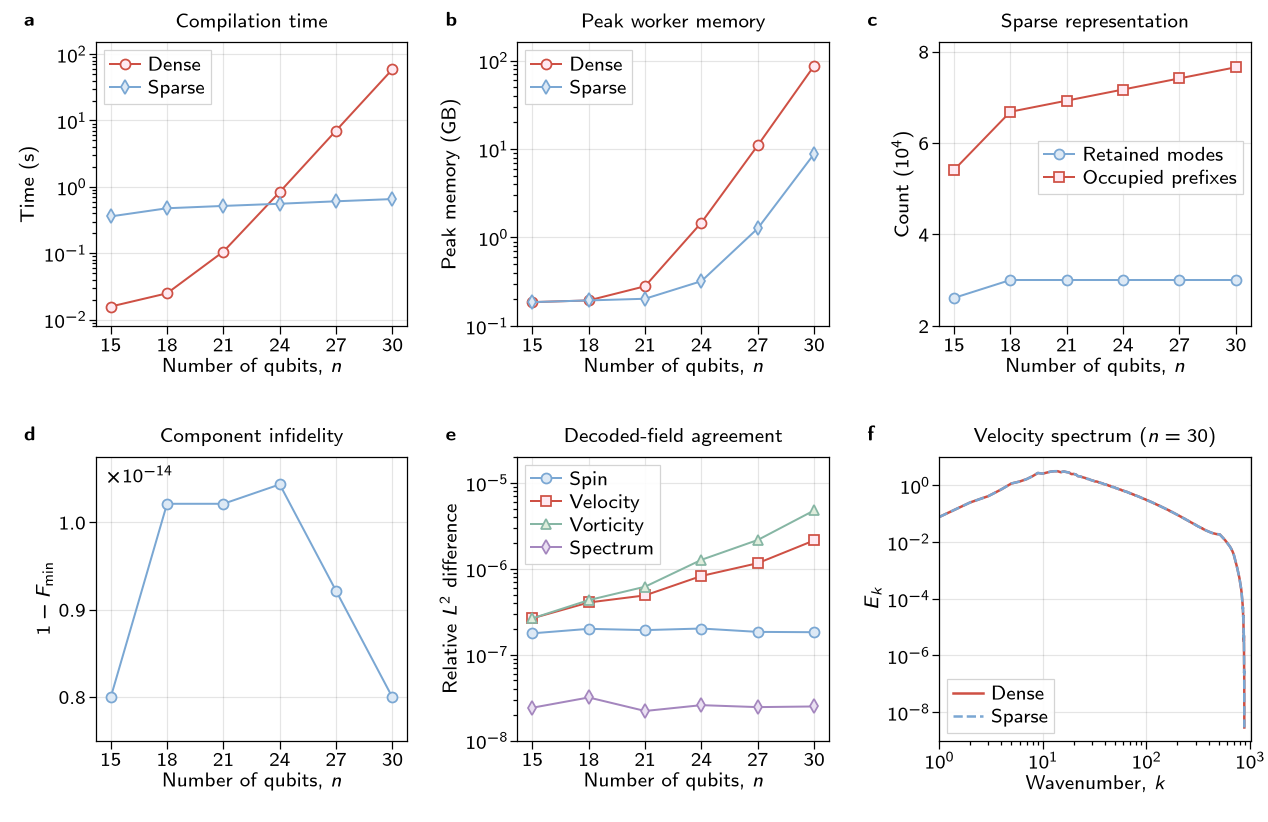

In [4]:
pdf_path = OUTPUT_DIR / "dense_sparse_consistency.pdf"
png_path = OUTPUT_DIR / "dense_sparse_consistency.png"

# Explicit bbox_inches=None preserves the requested physical dimensions.
fig.savefig(pdf_path, format="pdf", transparent=True, bbox_inches=None)
fig.savefig(
    png_path, format="png", dpi=EXPORT_DPI,
    facecolor="white", transparent=False, bbox_inches=None,
)
print(f"Saved vector PDF: {pdf_path}")
print(f"Saved {EXPORT_DPI} dpi PNG: {png_path}")
print(f"Canvas: {FIGURE_WIDTH_CM:.1f} cm x {FIGURE_HEIGHT_CM:.1f} cm; text: 8 pt")
plt.show()
